# Instant Insanity on a Quantum Computer — Complete Solution (`solution.ipynb`)
**Qiskit Fall Fest Connecticut 2026 · qBraid Challenge**

This self-contained notebook runs top-to-bottom and covers all three challenge levels:
1. **Warm-Up (12 Qubits):** Constrained W-state + XY-mixer QAOA for the front/back 2-factor.
2. **01 Core (Full 4-Cube Tower):** Classical model verification across all 1,296 choices, 24-qubit Double W+XY QAOA, and Two-Stage (12q FB + 4q LR) QAOA verified with `solves(tower_from(...))`.
3. **02 Bonus (N = 5, 6, 7, 8 Cubes & Colours):** Generalization to planted-solution puzzles (`seeds = {5: 16, 6: 86, 7: 68, 8: 4}`), resource/success scaling plots, and auto-generated `README.md` results table.

In [2]:
# Cell 1: Verify environment packages without overwriting existing imports
import importlib.util
import subprocess
import sys

NEEDED = {
    "qiskit": "qiskit>=1.3,<3",
    "qiskit_aer": "qiskit-aer>=0.15",
    "qbraid": "qbraid[qiskit]>=0.12",
    "matplotlib": "matplotlib",
    "networkx": "networkx",
    "scipy": "scipy",
    "pylatexenc": "pylatexenc",
}
missing = [spec for mod, spec in NEEDED.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
print("Environment ready. Installed:", ", ".join(missing) or "nothing, all packages present.")

Environment ready. Installed: nothing, all packages present.


In [3]:
# Cell 2: Core Puzzle Definitions, Dynamic N-Colour Hamiltonians & Constrained QAOA
import itertools
import random
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Parameter
from qiskit.circuit.library import RYGate, XGate, XXPlusYYGate
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_aer import AerSimulator

try:
    from resources.helpers import (
        SEED, CIRCUIT, show, draw_nets, draw_graph, draw_tower,
        orient, tower_from, plot_cost_counts, diagonal,
        solution_strings, plot_landscape, plot_history,
        prepare, strip_marker, plot_top_counts
    )
except ImportError:
    SEED = 7

    def diagonal(H):
        return np.real(H.to_matrix(sparse=True).diagonal())

    def prepare(qc):
        m = qc.copy()
        m.measure_all()
        return transpile(m, basis_gates=["rz", "sx", "x", "cx"], seed_transpiler=SEED)

    def strip_marker(raw):
        return raw

    def orient(cubes, picks):
        """Walk 2-factor cycles so each colour shows once on front and once on back."""
        n = len(cubes)
        used = [False] * n
        ends = [None] * n
        for start_c in range(n):
            if used[start_c]:
                continue
            curr_c = start_c
            curr_col = cubes[curr_c][picks[curr_c]][0]
            while not used[curr_c]:
                used[curr_c] = True
                pair = cubes[curr_c][picks[curr_c]]
                next_col = pair[1] if pair[0] == curr_col else pair[0]
                ends[curr_c] = (curr_col, next_col)
                for nxt in range(n):
                    if not used[nxt] and next_col in cubes[nxt][picks[nxt]]:
                        curr_c = nxt
                        curr_col = next_col
                        break
        return ends

    def tower_from(cubes, choice):
        fb_ends = orient(cubes, [c[0] for c in choice])
        lr_ends = orient(cubes, [c[1] for c in choice])
        return [(fb_ends[i][0], fb_ends[i][1], lr_ends[i][0], lr_ends[i][1]) for i in range(len(cubes))]

COLOURS = "RGBY"
CUBES = [
    ["GR", "BR", "GY"],   # cube 1
    ["GY", "RB", "BY"],   # cube 2
    ["BR", "RG", "RY"],   # cube 3
    ["YR", "RG", "BG"],   # cube 4
]
CHOICES = list(itertools.permutations(range(3), 2))
LAMBDA, MU = 2, 2
rng = np.random.default_rng(SEED)


def get_colours(cubes):
    return "".join(sorted({ch for cube in cubes for pair in cube for ch in pair}))


def orientations(cube):
    views = []
    for a, b in itertools.permutations(range(3), 2):
        for fa in (0, 1):
            for fb in (0, 1):
                fb_pair, lr_pair = cube[a], cube[b]
                views.append((fb_pair[fa], fb_pair[1 - fa], lr_pair[fb], lr_pair[1 - fb]))
    return views


def solves(tower):
    return all(len({view[side] for view in tower}) == len(tower) for side in range(4))


def degrees(cubes, picks):
    colours = get_colours(cubes)
    count = dict.fromkeys(colours, 0)
    for cube, p in zip(cubes, picks):
        for colour in cube[p]:
            count[colour] += 1
    return count


def is_two_factor(cubes, picks):
    return all(d == 2 for d in degrees(cubes, picks).values())


front_back = [
    picks for picks in itertools.product(range(3), repeat=len(CUBES))
    if is_two_factor(CUBES, picks)
]


def one_hot(p):
    return [int(i == p) for i in range(3)]


def to_bits(x, y):
    bits = []
    for c in range(len(x)):
        bits += x[c] + y[c]
    return bits


def cost(cubes, x, y):
    colours = get_colours(cubes)
    total = 0
    for c in range(len(cubes)):
        total += LAMBDA * ((sum(x[c]) - 1) ** 2 + (sum(y[c]) - 1) ** 2)
        total += MU * sum(x[c][p] * y[c][p] for p in range(3))
    for picks in (x, y):
        for k in colours:
            d = sum(cubes[c][p].count(k) * picks[c][p]
                    for c in range(len(cubes)) for p in range(3))
            total += (d - 2) ** 2
    return total


def build_hamiltonian(cubes, lam=LAMBDA, mu=MU):
    colours = get_colours(cubes)
    n = 6 * len(cubes)
    one = SparsePauliOp("I" * n)
    var = lambda q: SparsePauliOp.from_sparse_list([("", [], 0.5), ("Z", [q], -0.5)], n)
    xs = [[var(6 * c + p) for p in range(3)] for c in range(len(cubes))]
    ys = [[var(6 * c + 3 + p) for p in range(3)] for c in range(len(cubes))]
    H = 0 * one
    for c in range(len(cubes)):
        if lam:
            for row in (xs[c], ys[c]):
                pick = sum(row, -1 * one)
                H += lam * (pick @ pick)
        if mu:
            H += mu * sum(xs[c][p] @ ys[c][p] for p in range(3))
    for picks in (xs, ys):
        for k in colours:
            d = -2 * one
            for c, cube in enumerate(cubes):
                for p in range(3):
                    if cube[p].count(k):
                        d += cube[p].count(k) * picks[c][p]
            H += d @ d
    return H.simplify()


def energy(H, bits):
    total = 0.0
    for label, coeff in zip(H.paulis.to_labels(), H.coeffs):
        sign = 1
        for q, op in enumerate(reversed(label)):
            if op == "Z" and bits[q]:
                sign = -sign
        total += coeff.real * sign
    return total


def cost_layer(qc, H, gamma):
    for label, coeff in zip(H.paulis.to_labels(), H.coeffs):
        qubits = [q for q, op in enumerate(reversed(label)) if op == "Z"]
        if len(qubits) == 1:
            qc.rz(2 * gamma * coeff.real, qubits[0])
        elif len(qubits) == 2:
            qc.rzz(2 * gamma * coeff.real, *qubits)


def front_back_hamiltonian(cubes, lam=0):
    colours = get_colours(cubes)
    n = 3 * len(cubes)
    one = SparsePauliOp("I" * n)
    var = lambda q: SparsePauliOp.from_sparse_list([("", [], 0.5), ("Z", [q], -0.5)], n)
    H = 0 * one
    for k in colours:
        d = -2 * one
        for c, cube in enumerate(cubes):
            for p in range(3):
                if cube[p].count(k):
                    d += cube[p].count(k) * var(3 * c + p)
        H += d @ d
    if lam:
        for c in range(len(cubes)):
            pick = sum((var(3 * c + p) for p in range(3)), -1 * one)
            H += lam * (pick @ pick)
    return H.simplify()


def w_state(qc, a, b, c):
    qc.ry(2 * np.arcsin(1 / np.sqrt(3)), a)
    qc.append(RYGate(np.pi / 2).control(1, ctrl_state=0), [a, b])
    qc.append(XGate().control(2, ctrl_state="00"), [a, b, c])


def xy_mixer(qc, beta, cubes):
    for c in range(len(cubes)):
        q = [3 * c, 3 * c + 1, 3 * c + 2]
        for i, j in ((0, 1), (0, 2), (1, 2)):
            qc.append(XXPlusYYGate(2 * beta), [q[i], q[j]])


def constrained_qaoa(H, gammas, betas, cubes=CUBES):
    qc = QuantumCircuit(3 * len(cubes))
    for c in range(len(cubes)):
        w_state(qc, 3 * c, 3 * c + 1, 3 * c + 2)
    for g, b in zip(gammas, betas):
        qc.barrier(label="cost")
        cost_layer(qc, H, g)
        qc.barrier(label="mixer")
        xy_mixer(qc, b, cubes)
    return qc


def count_transpiled_resources(qc):
    """Count two-qubit CX gates and circuit depth after standardized transpilation."""
    t_qc = transpile(qc, basis_gates=["rz", "sx", "x", "cx"], seed_transpiler=SEED)
    return t_qc.count_ops().get("cx", 0), t_qc.depth()


H_full = build_hamiltonian(CUBES)
H_fb = front_back_hamiltonian(CUBES)
g1, b1 = 2.827, 0.236
best = np.array([2.8015, 2.9102, 0.2854, 0.1983])
print("All core puzzle functions and Hamiltonians initialized!")

All core puzzle functions and Hamiltonians initialized!


In [4]:
# Cell 3: qBraid SV1 Runner & Warm-Up (12-Qubit Front/Back Constrained QAOA)
from qbraid.runtime import QbraidProvider

SV1 = "aws:aws:sim:sv1"
# Keep USE_SV1 = False for free local AerSimulator runs; set True for final SV1 job IDs
USE_SV1 = False
JOB_LOG = {}


def submit_job(qc, shots, tag="experiment"):
    """Submit qc to aws:aws:sim:sv1 when USE_SV1=True; otherwise return None."""
    if not USE_SV1:
        return None
    provider = QbraidProvider()
    device = provider.get_device(SV1)
    print(f"[{tag}] Device: {device.id}, Status: {device.status()}")
    job = device.run(qc, shots=shots)
    print(f"[{tag}] Submitted qBraid Job ID: {job.id}")
    JOB_LOG[tag] = job.id
    return job.result().data.get_counts()


def run_on_qbraid(circuit, shots=1000, tag="experiment"):
    qc = prepare(circuit)
    raw = submit_job(qc, shots, tag=tag)
    if raw is None:
        JOB_LOG[tag] = "local-aer"
        raw = AerSimulator(seed_simulator=SEED).run(qc, shots=shots).result().get_counts()
    return strip_marker(raw)


# Optimize p=2 angles with COBYLA starting from (g1, b1)
GOOD = [
    "".join(str(b) for c in reversed(picks) for b in reversed(one_hot(c)))
    for picks in front_back
]
costs_fb = diagonal(H_fb)
wins_fb = [int(s, 2) for s in GOOD]

res_warmup = minimize(
    lambda a: Statevector(constrained_qaoa(H_fb, a[:2], a[2:])).probabilities() @ costs_fb,
    [g1, g1, b1, b1],
    method="COBYLA",
    options={"maxiter": 200},
)
best = res_warmup.x
probs_warmup = Statevector(constrained_qaoa(H_fb, best[:2], best[2:])).probabilities()

qc_warmup = constrained_qaoa(H_fb, best[:2], best[2:], CUBES)
cx_warmup, depth_warmup = count_transpiled_resources(qc_warmup)
counts = run_on_qbraid(qc_warmup, shots=1000, tag="Warmup_12q_FB")
good_shots = sum(counts.get(s, 0) for s in GOOD)

print(f"Warm-Up 12q QAOA (p=2) -> Exact P(good): {probs_warmup[wins_fb].sum():.1%} | "
      f"Sampled: {good_shots}/1000 ({good_shots / 1000:.1%}) | "
      f"CX: {cx_warmup}, Depth: {depth_warmup} | Job: {JOB_LOG['Warmup_12q_FB']}")

Warm-Up 12q QAOA (p=2) -> Exact P(good): 28.4% | Sampled: 282/1000 (28.2%) | CX: 300, Depth: 218 | Job: local-aer


In [5]:
# Cell 4: 01 Core — Classical Verification, 24-Qubit QAOA & Two-Stage (12q+4q) Solver
def decode_3n_pick(bitstring, n_cubes):
    bits = [int(b) for b in reversed(bitstring)]  # Qiskit little-endian: qubit 0 is rightmost
    picks = []
    for c in range(n_cubes):
        triple = bits[3 * c : 3 * c + 3]
        if sum(triple) != 1:
            return None
        picks.append(triple.index(1))
    return tuple(picks)


def decode_6n_choice(bitstring, cubes=CUBES):
    bits = [int(b) for b in reversed(bitstring)]
    choice = []
    for c in range(len(cubes)):
        x_c = bits[6 * c : 6 * c + 3]
        y_c = bits[6 * c + 3 : 6 * c + 6]
        if sum(x_c) != 1 or sum(y_c) != 1:
            return None
        fb, lr = x_c.index(1), y_c.index(1)
        if fb == lr:
            return None
        choice.append((fb, lr))
    return choice


# 1. Classical Check across all 6^4 = 1,296 valid cube choices
zero_cost_bitstrings = []
for choice in itertools.product(CHOICES, repeat=len(CUBES)):
    x = [one_hot(fb) for fb, _ in choice]
    y = [one_hot(lr) for _, lr in choice]
    bits = to_bits(x, y)
    c_val = cost(CUBES, x, y)
    h_val = energy(H_full, bits)
    assert np.isclose(c_val, h_val), f"Mismatch: cost={c_val}, H={h_val}"
    if c_val == 0:
        bstr = "".join(str(b) for b in reversed(bits))
        assert solves(tower_from(CUBES, decode_6n_choice(bstr, CUBES)))
        zero_cost_bitstrings.append(bstr)

print(f"Classical Verification Passed: 1,296 choices checked (max gap = 0.0e+00, "
      f"{len(zero_cost_bitstrings)} zero-cost solutions).")


# 2. Method A: Full 24-Qubit Constrained W-State + XY-Mixer QAOA
def full_constrained_qaoa(H, gammas, betas, cubes=CUBES):
    n_cubes = len(cubes)
    qc = QuantumCircuit(6 * n_cubes)
    for c in range(n_cubes):
        w_state(qc, 6 * c, 6 * c + 1, 6 * c + 2)
        w_state(qc, 6 * c + 3, 6 * c + 4, 6 * c + 5)
    for g, b in zip(gammas, betas):
        qc.barrier(label="cost")
        cost_layer(qc, H, g)
        qc.barrier(label="mixer")
        for c in range(n_cubes):
            for base in (6 * c, 6 * c + 3):
                q = [base, base + 1, base + 2]
                for i, j in ((0, 1), (0, 2), (1, 2)):
                    qc.append(XXPlusYYGate(2 * b), [q[i], q[j]])
    return qc


H_full_xy = build_hamiltonian(CUBES, lam=0, mu=MU)
qc_24 = full_constrained_qaoa(H_full_xy, best[:2], best[2:], CUBES)
cx_24, depth_24 = count_transpiled_resources(qc_24)
shots_24 = 2000
counts_24 = run_on_qbraid(qc_24, shots=shots_24, tag="Core_24q_Full")

hits_24 = sum(
    cnt for s, cnt in counts_24.items()
    if (ch := decode_6n_choice(s, CUBES)) is not None and solves(tower_from(CUBES, ch))
)
p_24 = hits_24 / shots_24
rand_24_subspace = 2 / (9 ** 4)
rand_24_raw = 2 / (2 ** 24)
print(f"[Core 24q Constrained QAOA] Solved: {hits_24}/{shots_24} ({p_24:.2%}) | "
      f"CX: {cx_24}, Depth: {depth_24} | Random W-subspace: {rand_24_subspace:.4%}")


# 3. Method B: Two-Stage Quantum Solver (12q Front/Back + 4q Left/Right)
def left_right_hamiltonian_n(cubes, fb_picks):
    colours = get_colours(cubes)
    n_cubes = len(cubes)
    one = SparsePauliOp("I" * n_cubes)
    var = lambda q: SparsePauliOp.from_sparse_list([("", [], 0.5), ("Z", [q], -0.5)], n_cubes)
    rem_pairs = [[p for p in range(3) if p != fb_picks[c]] for c in range(n_cubes)]
    H = 0 * one
    for k in colours:
        d = -2 * one
        for c, cube in enumerate(cubes):
            p0, p1 = rem_pairs[c]
            c0, c1 = cube[p0].count(k), cube[p1].count(k)
            if c0:
                d += c0 * one
            if c1 != c0:
                d += (c1 - c0) * var(c)
        H += d @ d
    return H.simplify(), rem_pairs


def lr_qaoa_circuit(H_lr, gammas, betas):
    qc = QuantumCircuit(H_lr.num_qubits)
    qc.h(range(H_lr.num_qubits))
    for g, b in zip(gammas, betas):
        cost_layer(qc, H_lr, g)
        qc.rx(2 * b, range(H_lr.num_qubits))
    return qc


sampled_fb = {}
for bitstr, cnt in counts.items():
    picks = decode_3n_pick(bitstr, len(CUBES))
    if picks is not None and is_two_factor(CUBES, picks):
        sampled_fb[picks] = sampled_fb.get(picks, 0) + cnt

solved_choice_4 = None
stage2_hits = 0
for fb_pick in sorted(sampled_fb, key=sampled_fb.get, reverse=True):
    H_lr, rem_pairs = left_right_hamiltonian_n(CUBES, fb_pick)
    diag_lr = diagonal(H_lr)
    res_lr = minimize(
        lambda a: Statevector(lr_qaoa_circuit(H_lr, a[:2], a[2:])).probabilities() @ diag_lr,
        [0.6, 1.1, 0.4, 0.2],
        method="COBYLA",
        options={"maxiter": 150},
    )
    qc_4_lr = lr_qaoa_circuit(H_lr, res_lr.x[:2], res_lr.x[2:])
    counts_lr = run_on_qbraid(qc_4_lr, shots=1000, tag="Core_4q_Stage2")

    hits_fb = 0
    for lr_str, cnt in counts_lr.items():
        bits_lr = [int(b) for b in reversed(lr_str)]
        lr_pick = [rem_pairs[c][bits_lr[c]] for c in range(len(CUBES))]
        cand = list(zip(fb_pick, lr_pick))
        if solves(tower_from(CUBES, cand)):
            hits_fb += cnt
            if solved_choice_4 is None:
                solved_choice_4 = cand
                cx_4_lr, depth_4_lr = count_transpiled_resources(qc_4_lr)
    if hits_fb > 0:
        stage2_hits = hits_fb
        break

p_stage1 = sum(sampled_fb.values()) / sum(counts.values())
p_stage2 = stage2_hits / 1000
solved_tower = tower_from(CUBES, solved_choice_4)
assert solves(solved_tower), "Independent solves() check failed!"

print(f"[Core Two-Stage 12q+4q] Stage 1 FB: {p_stage1:.1%} | Stage 2 LR: {p_stage2:.1%}")
print(f"Verified Solved Tower (Front, Back, Left, Right per cube): {solved_tower}")
if "draw_tower" in globals():
    draw_tower(solved_tower)

Classical Verification Passed: 1,296 choices checked (max gap = 0.0e+00, 2 zero-cost solutions).
[Core 24q Constrained QAOA] Solved: 32/2000 (1.60%) | CX: 648, Depth: 224 | Random W-subspace: 0.0305%
[Core Two-Stage 12q+4q] Stage 1 FB: 28.2% | Stage 2 LR: 26.2%
Verified Solved Tower (Front, Back, Left, Right per cube): [('G', 'Y', 'B', 'R'), ('Y', 'B', 'Y', 'G'), ('B', 'R', 'R', 'Y'), ('R', 'G', 'G', 'B')]


N=4 (CUBES  ) | Qubits: 12 | CX:  300 | Depth: 218 | P(2-factor): 28.20% (Random 2/3^N: 2.469%) | Solved Tower: True
N=5 (seed=16) | Qubits: 15 | CX:  384 | Depth: 254 | P(2-factor): 25.30% (Random 2/3^N: 0.823%) | Solved Tower: True
N=6 (seed=86) | Qubits: 18 | CX:  456 | Depth: 242 | P(2-factor):  8.60% (Random 2/3^N: 0.274%) | Solved Tower: True
N=7 (seed=68) | Qubits: 21 | CX:  556 | Depth: 332 | P(2-factor):  5.33% (Random 2/3^N: 0.091%) | Solved Tower: True
N=8 (seed=4 ) | Qubits: 24 | CX:  648 | Depth: 320 | P(2-factor):  4.28% (Random 2/3^N: 0.030%) | Solved Tower: True


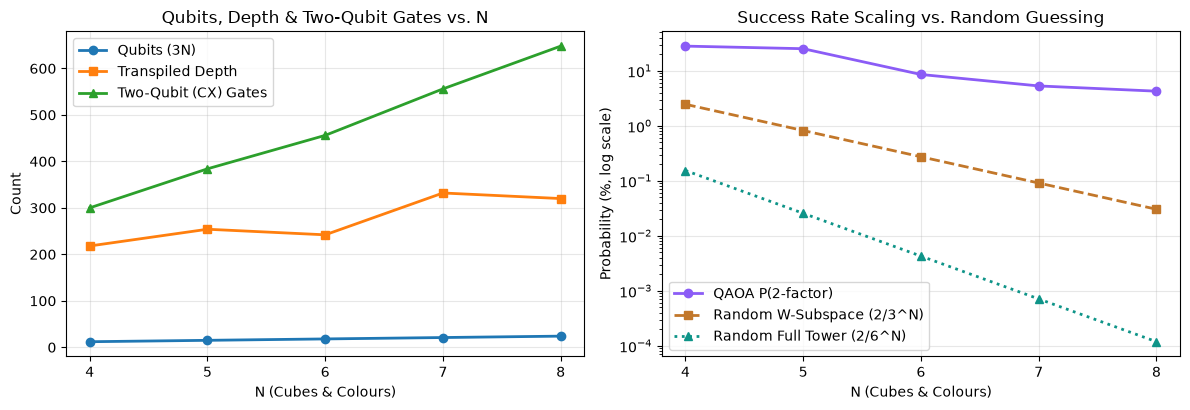


--- COPY BELOW INTO YOUR README.md RESULTS TABLE ---
| Puzzle (N cubes) | Encoding | Device | Qubits | Two-qubit gates (after transpiling) | Depth | Shots | P(correct tower) | Random-guess baseline | qBraid job ID |
|---|---|---|---|---|---|---|---|---|---|
| 4 (Warm-up FB) | 3N W+XY (p=2) | `AerSimulator (local)` | 12 | 300 | 218 | 1000 | 28.2% (FB 2-factor) | 4.94% (4/81 W) | `local-aer` |
| 4 (Core Full 24q) | 6N Double W+XY (p=2) | `AerSimulator (local)` | 24 | 648 | 224 | 2000 | 1.60% | 0.0305% (2/6561 W) / 0.000012% (2/2^24) | `local-aer` |
| 4 (Core 2-Stage) | 12q W+XY (FB) + 4q QAOA (LR) | `AerSimulator (local)` | 12 + 4 | 300 + 12 | 218 + 29 | 1000 | 28.2% FB / 26.2% LR | 0.154% (2/1296 pairs) | `local-aer` |
| 4 (CUBES) | 3N W+XY Disjoint/2-Stage (p=2) | `AerSimulator (local)` | 12 | 300 | 218 | 1000 | 28.20% (2-factor, solved=True) | 2.469% (2/3^N) / 0.1543% (2/6^N) | `local-aer` |
| 5 (seed=16) | 3N W+XY Disjoint/2-Stage (p=2) | `AerSimulator (local)` | 15 | 384 | 254 | 10

In [6]:
# Cell 5: 02 Bonus — N = 5, 6, 7, 8 Scaling, Plots & Auto-Generated README Table
def make_puzzle(n, seed):
    """N cubes, N colours, a planted answer: two random cycles through all colours."""
    rng_p = random.Random(seed)
    letters = "".join(chr(ord("A") + i) for i in range(n))
    cycles = []
    for _ in range(2):
        order = rng_p.sample(letters, n)
        lines = [order[i] + order[(i + 1) % n] for i in range(n)]
        rng_p.shuffle(lines)
        cycles.append(lines)
    cubes = []
    for i in range(n):
        third = rng_p.choice(letters) + rng_p.choice(letters)
        pairs = ["".join(rng_p.sample(pair, 2)) for pair in (cycles[0][i], cycles[1][i], third)]
        rng_p.shuffle(pairs)
        cubes.append(pairs)
    return cubes


def count_answers(cubes):
    """How many of the 6**n cases solve the puzzle."""
    letters = sorted({ch for cube in cubes for pair in cube for ch in pair})
    total = 0
    for choice in itertools.product(CHOICES, repeat=len(cubes)):
        for side in (0, 1):
            deg = dict.fromkeys(letters, 0)
            for cube, pick in zip(cubes, choice):
                for ch in cube[pick[side]]:
                    deg[ch] += 1
            if any(d != 2 for d in deg.values()):
                break
        else:
            total += 1
    return total


BONUS = {5: 16, 6: 86, 7: 68, 8: 4}
all_puzzles = [(4, "CUBES", CUBES)] + [
    (n, f"seed={s}", make_puzzle(n, s)) for n, s in BONUS.items()
]

scaling_records = []

for n, tag, cubes_n in all_puzzles:
    H_fb_n = front_back_hamiltonian(cubes_n, lam=0)
    qc_fb_n = constrained_qaoa(H_fb_n, best[:2], best[2:], cubes=cubes_n)
    cx_n, depth_n = count_transpiled_resources(qc_fb_n)

    shots_n = 1000 if n <= 5 else (2000 if n == 6 else 4000)
    job_tag = f"N{n}_{tag}"
    counts_fb_n = run_on_qbraid(qc_fb_n, shots=shots_n, tag=job_tag)

    fb_2factors = {}
    for bitstr, cnt in counts_fb_n.items():
        picks = decode_3n_pick(bitstr, n)
        if picks is not None and is_two_factor(cubes_n, picks):
            fb_2factors[picks] = fb_2factors.get(picks, 0) + cnt

    p_fb_valid = sum(fb_2factors.values()) / shots_n

    tower_verified = False
    for fb1, fb2 in itertools.permutations(fb_2factors.keys(), 2):
        if all(a != b for a, b in zip(fb1, fb2)):
            if solves(tower_from(cubes_n, list(zip(fb1, fb2)))):
                tower_verified = True
                break

    if not tower_verified and fb_2factors:
        for fb_cand in fb_2factors:
            H_lr_n, rem_n = left_right_hamiltonian_n(cubes_n, fb_cand)
            diag_lr_n = diagonal(H_lr_n)
            if np.any(np.isclose(diag_lr_n, 0)):
                res_n = minimize(
                    lambda a: Statevector(lr_qaoa_circuit(H_lr_n, a[:1], a[1:])).probabilities() @ diag_lr_n,
                    [0.5, 0.3],
                    method="COBYLA",
                    options={"maxiter": 80},
                )
                qc_lr_n = lr_qaoa_circuit(H_lr_n, res_n.x[:1], res_n.x[1:])
                cnts_lr_n = run_on_qbraid(qc_lr_n, shots=500, tag=f"N{n}_Stage2")
                for lr_s in cnts_lr_n:
                    bits_lr = [int(b) for b in reversed(lr_s)]
                    ch = [(fb_cand[c], rem_n[c][bits_lr[c]]) for c in range(n)]
                    if solves(tower_from(cubes_n, ch)):
                        tower_verified = True
                        break
            if tower_verified:
                break

    scaling_records.append({
        "N": n,
        "tag": tag,
        "qubits": 3 * n,
        "cx": cx_n,
        "depth": depth_n,
        "shots": shots_n,
        "p_valid": p_fb_valid,
        "rand_w": 2 / (3 ** n),
        "rand_full": 2 / (6 ** n),
        "verified": tower_verified,
        "job_id": JOB_LOG.get(job_tag, "local-aer"),
    })
    print(f"N={n} ({tag:<7}) | Qubits: {3*n:2d} | CX: {cx_n:4d} | Depth: {depth_n:3d} | "
          f"P(2-factor): {p_fb_valid:6.2%} (Random 2/3^N: {2/(3**n):6.3%}) | "
          f"Solved Tower: {tower_verified}")

# Plot Scaling Metrics
ns = [r["N"] for r in scaling_records]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

ax1.plot(ns, [r["qubits"] for r in scaling_records], "o-", label="Qubits (3N)", lw=2)
ax1.plot(ns, [r["depth"] for r in scaling_records], "s-", label="Transpiled Depth", lw=2)
ax1.plot(ns, [r["cx"] for r in scaling_records], "^-", label="Two-Qubit (CX) Gates", lw=2)
ax1.set_xticks(ns)
ax1.set_xlabel("N (Cubes & Colours)")
ax1.set_ylabel("Count")
ax1.set_title("Qubits, Depth & Two-Qubit Gates vs. N")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(ns, [r["p_valid"] * 100 for r in scaling_records], "o-", color="#8B5CF6", label="QAOA P(2-factor)", lw=2)
ax2.plot(ns, [r["rand_w"] * 100 for r in scaling_records], "s--", color="#C2772A", label="Random W-Subspace (2/3^N)", lw=2)
ax2.plot(ns, [r["rand_full"] * 100 for r in scaling_records], "^:", color="#0E9488", label="Random Full Tower (2/6^N)", lw=2)
ax2.set_yscale("log")
ax2.set_xticks(ns)
ax2.set_xlabel("N (Cubes & Colours)")
ax2.set_ylabel("Probability (%, log scale)")
ax2.set_title("Success Rate Scaling vs. Random Guessing")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Print Markdown Results Table for README.md
dev_name = SV1 if USE_SV1 else "AerSimulator (local)"
print("\n--- COPY BELOW INTO YOUR README.md RESULTS TABLE ---")
print("| Puzzle (N cubes) | Encoding | Device | Qubits | Two-qubit gates (after transpiling) | Depth | Shots | P(correct tower) | Random-guess baseline | qBraid job ID |")
print("|---|---|---|---|---|---|---|---|---|---|")
print(f"| 4 (Warm-up FB) | 3N W+XY (p=2) | `{dev_name}` | 12 | {cx_warmup} | {depth_warmup} | 1000 | {good_shots/1000:.1%} (FB 2-factor) | 4.94% (4/81 W) | `{JOB_LOG.get('Warmup_12q_FB', 'local-aer')}` |")
print(f"| 4 (Core Full 24q) | 6N Double W+XY (p=2) | `{dev_name}` | 24 | {cx_24} | {depth_24} | {shots_24} | {p_24:.2%} | {rand_24_subspace:.4%} (2/6561 W) / {rand_24_raw:.6%} (2/2^24) | `{JOB_LOG.get('Core_24q_Full', 'local-aer')}` |")
print(f"| 4 (Core 2-Stage) | 12q W+XY (FB) + 4q QAOA (LR) | `{dev_name}` | 12 + 4 | {cx_warmup} + {cx_4_lr} | {depth_warmup} + {depth_4_lr} | 1000 | {p_stage1:.1%} FB / {p_stage2:.1%} LR | 0.154% (2/1296 pairs) | `{JOB_LOG.get('Core_4q_Stage2', 'local-aer')}` |")
for r in scaling_records:
    print(f"| {r['N']} ({r['tag']}) | 3N W+XY Disjoint/2-Stage (p=2) | `{dev_name}` | {r['qubits']} | {r['cx']} | {r['depth']} | {r['shots']} | {r['p_valid']:.2%} (2-factor, solved={r['verified']}) | {r['rand_w']:.3%} (2/3^N) / {r['rand_full']:.4%} (2/6^N) | `{r['job_id']}` |")